# Notebook 09: The Price Impact of Metaorders

**References:** Tóth, B., Lempérière, Y., Deremble, C., de Lataillade, J., Kockelkoren, J. and Bouchaud, J.-P. (2011). Anomalous price impact and the critical nature of liquidity in financial markets. *Physical Review X*, 1(2), 021006. Bouchaud, J.-P., Bonart, J., Donier, J. and Gould, M. (2018). *Trades, Quotes and Prices: Financial Markets Under the Microscope*. Cambridge University Press.

A large order is rarely sent at once: it is split into a **metaorder**, a sequence of smaller orders over time. Empirically, the price move a metaorder causes by the time it is done grows roughly like the **square root** of its size, $I(Q) \approx Y \sigma \sqrt{Q / V}$ (with $V$ the volume the market trades meanwhile), across markets and over a wide range of participation rates, and part of it reverts after the metaorder ends (Tóth et al. 2011; Bouchaud et al. 2018 review the evidence). Notebook 05 found the impact of *single* market orders concave in most models; this notebook asks whether the models reproduce the square-root law for metaorders.

**Method** (`lob/impact.py`). A metaorder of $Q$ lots goes out as equal market orders spread evenly over 20,000 model events: as many as the market trades lots in that time divided by 20 (at least 10, at most 100), so that each is a few lots and none clears the book on its own. Its impact is the mid-price move it causes, measured against a *twin* run that starts from the same book, model and random state but sends nothing: the difference between the two mid-prices removes most of the price noise the market adds anyway. The runs drift apart as the metaorder changes the book, so the pairing reduces the noise without removing it. Each model is warmed up for 5,000 events first. Sizes are chosen per model to give the same **participation rates**, $Q / (Q + V)$, of 5%, 10%, 20% and 30%, from a pilot measurement of $V$ (the models trade at very different rates), so the models are compared like with like. If $I \propto Q^{\delta}$, a log-log fit gives $\delta$: about 0.5 for the square-root law, 1 for linear impact.

In [1]:
import os
import sys
import warnings
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed

from lob.impact import paired_metaorders, warmed_market
from lob.models.zero_intelligence import SmithFarmerModel
from lob.models.hawkes import HawkesZIModel
from lob.models.mike_farmer import MikeFarmer2008Model
from lob.analysis.plotting import set_style

set_style()

# Notebook 05's models and parameters. Parlour's rule is left out: its book is too thin for
# metaorders (one of moderate size often empties a side, leaving no mid-price to measure).
ZI_PARAMS = dict(mu=1.0, lam=0.5, delta=0.1, price_range=50, initial_mid=10000)
MODELS = {
    'ZI (Smith et al.)': lambda: SmithFarmerModel(**ZI_PARAMS),
    'ZI + Hawkes': lambda: HawkesZIModel(branching=0.8, decay=0.5, **ZI_PARAMS),
    'Mike-Farmer (2008 structure)': lambda: MikeFarmer2008Model(initial_mid=10000),
}
HORIZON = 20_000  # events over which a metaorder is executed in the main design
TARGETS = [0.05, 0.10, 0.20, 0.30]  # participation rates
AFTER = 5_000  # events after the end, for the decay
SEEDS = list(range(1, 65))
PILOT_SEEDS = list(range(101, 109))
MAX_LOST = 0.10  # a size is left out if more than this share of runs empties a side of the book

N_JOBS = min(8, os.cpu_count() or 1)
warnings.filterwarnings("ignore", message="A worker stopped while some jobs were given to the executor")


def measure(make_model, seed, sizes, children, spacing, after):
    start = warmed_market(make_model, seed)
    return [dict(seed=seed, size=r.size, impact=r.impact_end, later=r.impact_after[after], cost=r.cost,
                 volume=r.market_volume) for r in paired_metaorders(start, sizes, children, spacing, after=(after,))]


def run(make_model, seeds, sizes, children, spacing, after=AFTER):
    rows = Parallel(n_jobs=N_JOBS)(delayed(measure)(make_model, s, sizes, children, spacing, after) for s in seeds)
    return pd.DataFrame([r for runs in rows for r in runs])


def fit_slope(table, n_boot=2_000, seed=0):
    # delta from a log-log fit of the mean impact on the size, over the sizes kept (enough runs
    # with both sides of the book quoted, and at least three sizes); a 95% interval from resampling seeds.
    lost = table.groupby('size')['impact'].apply(lambda s: s.isna().mean())
    kept = sorted(lost.index[lost <= MAX_LOST])
    left_out = sorted(set(lost.index) - set(kept))
    if len(kept) < 3:
        return dict(delta=np.nan, lo=np.nan, hi=np.nan, kept=kept, left_out=left_out)
    wide = table[table['size'].isin(kept)].pivot_table(index='seed', columns='size', values='impact')

    def slope(frame):
        means = frame.mean(axis=0)
        if (means <= 0).any():
            return np.nan
        return np.polyfit(np.log(means.index.to_numpy(float)), np.log(means.to_numpy()), 1)[0]

    rng = np.random.default_rng(seed)
    boots = np.array([slope(wide.iloc[rng.integers(0, len(wide), len(wide))]) for _ in range(n_boot)])
    boots = boots[np.isfinite(boots)]
    return dict(delta=slope(wide), lo=np.percentile(boots, 2.5), hi=np.percentile(boots, 97.5), kept=kept,
                left_out=left_out)


def verdict(f):
    if len(f['kept']) < 3:
        return 'not resolved (fewer than three sizes kept)'
    sqrt_in, linear_in = f['lo'] <= 0.5 <= f['hi'], f['lo'] <= 1.0 <= f['hi']
    if f['lo'] > 0.5 and linear_in:
        return 'linear, not the square root'
    if f['lo'] > 1.0:
        return 'steeper than linear'
    if sqrt_in and not linear_in:
        return 'the square root'
    return 'not decided'

## 1. Impact Against Size at Matched Participation Rates

A pilot run of each model (8 other seeds) measures $V$, the lots the market trades over the 20,000 events of the execution. That sets the number of child orders, and the sizes are the multiples of it closest to each target participation rate. Each size runs from the same 64 warmed-up starts as its twin.

In [2]:
results, sizes_of, volume_of, children_of = {}, {}, {}, {}
for name, make in MODELS.items():
    pilot = run(make, PILOT_SEEDS, [10], children=10, spacing=HORIZON // 10, after=1)
    V = pilot['volume'].mean()
    children = int(min(100, max(10, round(V / 20))))
    sizes = sorted({max(children, int(round(p / (1 - p) * V / children)) * children) for p in TARGETS})
    volume_of[name], sizes_of[name], children_of[name] = V, sizes, children
    results[name] = run(make, SEEDS, sizes, children=children, spacing=HORIZON // children)

rows = []
for name, table in results.items():
    for size, group in table.groupby('size'):
        imp = group['impact'].dropna()
        rows.append({'model': name, 'child orders': children_of[name], 'size (lots)': size,
                     'participation': size / (size + volume_of[name]),
                     'impact (ticks)': imp.mean(), 'SE': imp.std(ddof=1) / np.sqrt(len(imp)),
                     'runs with both sides quoted': f"{len(imp)}/{len(group)}"})
summary = pd.DataFrame(rows)
print("Lots the market trades during the 20,000 events:",
      ", ".join(f"{name} {V:,.0f}" for name, V in volume_of.items()))
summary.style.format({'participation': '{:.1%}', 'impact (ticks)': '{:.2f}', 'SE': '{:.2f}'}).hide(axis='index')

Lots the market trades during the 20,000 events: ZI (Smith et al.) 202, ZI + Hawkes 180, Mike-Farmer (2008 structure) 3,596


model,child orders,size (lots),participation,impact (ticks),SE,runs with both sides quoted
ZI (Smith et al.),10,10,4.7%,1.15,0.37,64/64
ZI (Smith et al.),10,20,9.0%,3.09,0.36,64/64
ZI (Smith et al.),10,50,19.9%,6.03,0.38,64/64
ZI (Smith et al.),10,90,30.9%,10.17,0.50,64/64
ZI + Hawkes,10,10,5.3%,1.17,0.52,64/64
ZI + Hawkes,10,20,10.0%,2.17,0.56,64/64
ZI + Hawkes,10,40,18.2%,4.72,0.52,64/64
ZI + Hawkes,10,80,30.8%,8.47,0.62,64/64
Mike-Farmer (2008 structure),100,200,5.3%,17.02,1.48,64/64
Mike-Farmer (2008 structure),100,400,10.0%,37.18,1.55,64/64


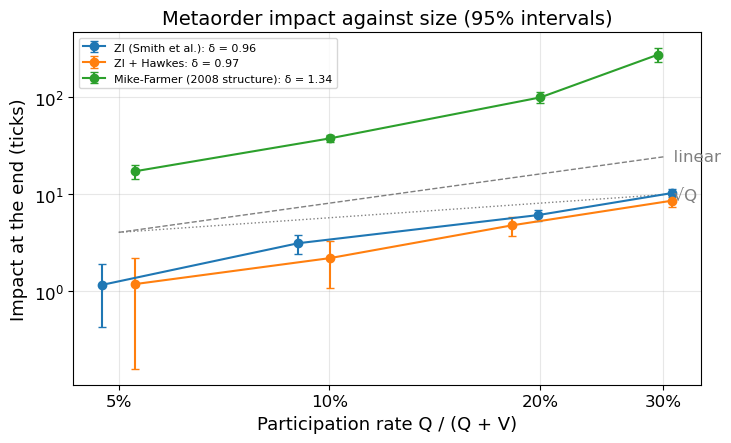

ZI (Smith et al.): δ = 0.96, 95% interval 0.77 to 1.32: linear, not the square root
ZI + Hawkes: δ = 0.97, 95% interval 0.67 to 1.63: linear, not the square root
Mike-Farmer (2008 structure): δ = 1.34, 95% interval 1.24 to 1.44: steeper than linear


In [3]:
fits = {name: fit_slope(table) for name, table in results.items()}

fig, ax = plt.subplots(figsize=(7.5, 4.6))
for i, (name, table) in enumerate(results.items()):
    kept = table[table['size'].isin(fits[name]['kept'])]
    stats = kept.groupby('size')['impact'].agg(['mean', 'std', 'count'])
    x = stats.index.to_numpy(float) / (stats.index.to_numpy(float) + volume_of[name])
    ax.errorbar(x, stats['mean'], yerr=1.96 * stats['std'] / np.sqrt(stats['count']), marker='o', capsize=3,
                color=f'C{i}', label=f"{name}: δ = {fits[name]['delta']:.2f}")
ax.set_xscale('log')
ax.set_yscale('log')
ref_x = np.array([0.05, 0.3])
for power, style in ((0.5, ':'), (1.0, '--')):
    ax.plot(ref_x, 4 * (ref_x / ref_x[0]) ** power, style, color='gray', linewidth=1)
ax.text(0.3, 4 * 6 ** 0.5, '  √Q', color='gray', va='center')
ax.text(0.3, 4 * 6, '  linear', color='gray', va='center')
ax.set_xticks(TARGETS, [f'{p:.0%}' for p in TARGETS])
ax.minorticks_off()
ax.set_xlabel('Participation rate Q / (Q + V)')
ax.set_ylabel('Impact at the end (ticks)')
ax.set_title('Metaorder impact against size (95% intervals)')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

for name, f in fits.items():
    left = (f" (left out, a side of the book empty in most runs: {', '.join(map(str, f['left_out']))} lots)"
            if f['left_out'] else '')
    print(f"{name}: δ = {f['delta']:.2f}, 95% interval {f['lo']:.2f} to {f['hi']:.2f}: {verdict(f)}{left}")

## 2. A Second Design: Fast Execution at High Participation

The result above contradicts the empirical square-root law (the 95% intervals exclude $\delta = 0.5$), so it is checked with an independent design: 20 market orders one every 100 events (2,000 events in all), fixed sizes from 20 to 400 lots, 48 other seeds. Over 2,000 events the market trades far less, so these metaorders are most of the trading (high participation): a regime where the square-root law is not expected to hold, but where a model with linear impact should stay linear.

In [4]:
FAST_SIZES = [20, 40, 100, 200, 400]
fast = {name: run(make, list(range(201, 249)), FAST_SIZES, children=20, spacing=100, after=1_000)
        for name, make in MODELS.items()}
fast_fits = {name: fit_slope(table) for name, table in fast.items()}
for name, f in fast_fits.items():
    V = fast[name]['volume'].mean()
    left = (f"; left out (a side of the book empty in most runs): {', '.join(map(str, f['left_out']))} lots"
            if f['left_out'] else '')
    print(f"{name}: the market trades {V:,.0f} lots meanwhile; δ = {f['delta']:.2f} "
          f"(95% interval {f['lo']:.2f} to {f['hi']:.2f}): {verdict(f)}{left}")

ZI (Smith et al.): the market trades 20 lots meanwhile; δ = 1.01 (95% interval 0.98 to 1.05): linear, not the square root
ZI + Hawkes: the market trades 19 lots meanwhile; δ = 1.08 (95% interval 1.03 to 1.13): steeper than linear
Mike-Farmer (2008 structure): the market trades 360 lots meanwhile; δ = 1.31 (95% interval 1.09 to 1.58): steeper than linear; left out (a side of the book empty in most runs): 400 lots


## 3. Does the Impact Decay?

In real markets part of a metaorder's impact reverts once it ends. Here the impact 5,000 events after the end is compared with the impact at the end, over the sizes kept in Section 1 (the ratio of the means, with a 95% interval from resampling seeds).

In [5]:
def remaining(table, kept, n_boot=2_000, seed=1):
    t = table[table['size'].isin(kept)].dropna(subset=['impact', 'later'])
    by_seed = t.groupby('seed')[['impact', 'later']].sum()
    rng = np.random.default_rng(seed)
    ratio = lambda f: f['later'].sum() / f['impact'].sum()  # noqa: E731
    boots = [ratio(by_seed.iloc[rng.integers(0, len(by_seed), len(by_seed))]) for _ in range(n_boot)]
    return ratio(by_seed), *np.percentile(boots, [2.5, 97.5])

decay = {name: remaining(table, fits[name]['kept']) for name, table in results.items()}
for name, (r, lo, hi) in decay.items():
    print(f"{name}: {r:.0%} of the impact remains 5,000 events later (95% interval {lo:.0%} to {hi:.0%})")

ZI (Smith et al.): 94% of the impact remains 5,000 events later (95% interval 90% to 99%)
ZI + Hawkes: 101% of the impact remains 5,000 events later (95% interval 91% to 112%)
Mike-Farmer (2008 structure): 100% of the impact remains 5,000 events later (95% interval 99% to 102%)


## 4. Why the Models Miss the Square Root

In all three models the order flow does not react to the metaorder: market orders and limit orders keep arriving as before, and limit orders are placed relative to the *current* best quotes (the zero-intelligence models) or the current same-side quote (Mike and Farmer). After each child order the book re-forms around the new price, so the move each child causes stays, and the moves add up: impact grows at least in proportion to size and does not revert. It grows faster than that in Mike and Farmer's model, where the largest metaorders come close to emptying a side of the book. The square-root law needs liquidity that responds to the price, for instance orders that traders hold back (outside the visible book) and reveal as the price moves toward them; Tóth et al. (2011) relate the square root to such latent liquidity, which these models lack.

The fill price against the mid at the start (`cost` in the tables of `lob/impact.py`) is not used to measure $\delta$: every child order also pays the spread, a fixed cost that does not grow with $Q$, which flattens the log-log slope at small sizes.

In [6]:
lines = []
for name in MODELS:
    f, g = fits[name], fast_fits[name]
    r, lo, hi = decay[name]
    lines.append(f"- {name}: δ = {f['delta']:.2f} ({f['lo']:.2f} to {f['hi']:.2f}) at 5% to 30% participation "
                 f"({children_of[name]} child orders), "
                 f"{g['delta']:.2f} ({g['lo']:.2f} to {g['hi']:.2f}) in the fast design: {verdict(f)}; "
                 f"{r:.0%} of the impact remains 5,000 events later.")
square_root = [name for name in MODELS if verdict(fits[name]) == 'the square root']
print("Conclusions:")
print("\n".join(lines))
print("\nNo model reproduces the square-root law." if not square_root else
      f"\nThe square-root law holds in: {', '.join(square_root)}.")

Conclusions:
- ZI (Smith et al.): δ = 0.96 (0.77 to 1.32) at 5% to 30% participation (10 child orders), 1.01 (0.98 to 1.05) in the fast design: linear, not the square root; 94% of the impact remains 5,000 events later.
- ZI + Hawkes: δ = 0.97 (0.67 to 1.63) at 5% to 30% participation (10 child orders), 1.08 (1.03 to 1.13) in the fast design: linear, not the square root; 101% of the impact remains 5,000 events later.
- Mike-Farmer (2008 structure): δ = 1.34 (1.24 to 1.44) at 5% to 30% participation (100 child orders), 1.31 (1.09 to 1.58) in the fast design: steeper than linear; 100% of the impact remains 5,000 events later.

No model reproduces the square-root law.
